In [11]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

# Surface Tracking: Energy Consumption

Two stiffnesses tracking the same slanted-obstacle reference: k = 8 N/m (soft) vs
k = 70 N/m (stiff). Energy is the actuators' total mechanical work — |tau · qdot|
summed over all 9 motors and integrated over the first 45 s — in joules.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.integrate import trapezoid as trapz

# Soft vs stiff comparison
k_values = [8, 70]
data = {}

for k in k_values:
    fname = os.path.join('outputs', 'surface_tracking', f'k{k}.npz')
    d = np.load(fname)
    data[k] = d
    print(f"Loaded {fname}: {len(d['t'])} samples")

Loaded outputs\surface_tracking\k8.npz: 24719 samples
Loaded outputs\surface_tracking\k70.npz: 20399 samples


k=8: Energy (0-45s) = 0.22 J
k=70: Energy (0-45s) = 0.43 J


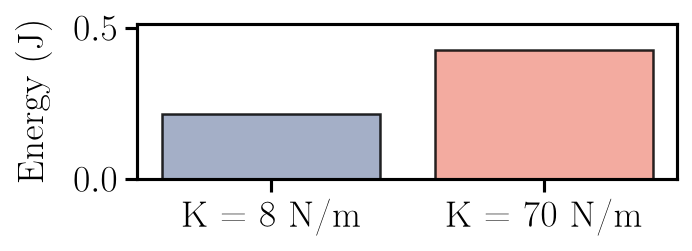


Energy ratio (stiff/soft): 1.98x


In [13]:
# Figure aspect ratio (width:height), as a ratio of two integers -- TUNE THIS.
ASPECT_W, ASPECT_H = 13, 4.5

YLABEL_PAD = 10  # pt -- TUNE THIS: space between 'Energy (J)' and the axis/tick numbers

# Energy: total |tau . qdot| (mechanical work, in joules), soft vs stiff, over the first 45 s
k_compare      = [8, 70]
colors_compare = [COLORS[3], COLORS[1]]
k_display      = {8: 8, 70: 70}
value_labels   = [f'K = {k_display[k]} N/m' for k in k_compare]

energy_values = {}

for k in k_compare:
    d    = data[k]
    t    = d['t'] - d['t'][0]
    tau  = d['tau']          # (n, 9) [N.m]
    qdot = d['q_motor_dot']  # (n, 9) [rad/s]

    idx_45s  = np.searchsorted(t, 45.0)
    t_window = t[:idx_45s]
    # per-motor mechanical power |tau * qdot| [W], summed across all 9 motors,
    # integrated over time -> total actuator work [J]
    power  = np.sum(np.abs(tau[:idx_45s] * qdot[:idx_45s]), axis=1)
    energy = trapz(power, t_window)
    energy_values[k] = energy
    print(f"k={k}: Energy (0-45s) = {energy:.2f} J")

FIG_W = FIG_W_SINGLE * 1.3
FIG_H = FIG_W * ASPECT_H / ASPECT_W
fig, ax_energy = plt.subplots(figsize=(FIG_W, FIG_H), layout='constrained')

ax_energy.bar(range(len(k_compare)), [energy_values[k] for k in k_compare],
              color=colors_compare, alpha=0.85, edgecolor='black', linewidth=1.2)
ax_energy.set_xticks(range(len(k_compare)))
ax_energy.set_xticklabels(value_labels)
ax_energy.set_ylabel('Energy (J)', labelpad=YLABEL_PAD)
ax_energy.grid(GRID, axis='y')

# No per-bar value labels (numbers are printed above instead), but keep the
# same headroom as before (*1.2, not the tighter *1.05) -- it's what put the
# 0.5 gridline at the top, which read better.
max_energy = max(energy_values.values())
ax_energy.set_ylim(0, max_energy * 1.2)

fig.savefig(os.path.join('outputs', 'surface_tracking', 'energy_comparison.pdf'))
plt.show()

print(f"\nEnergy ratio (stiff/soft): {energy_values[70] / energy_values[8]:.2f}x")